# Telco Customer Churn Prediction with a Simple ANN

**Goal:** predict which telecom customers will leave the company (*churn*), using a small neural network.
**Data:** [Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

## 01 — DATA UNDERSTANDING

### 1. Project Introduction

**The problem.** A telecom company loses customers every month. Keeping a customer is cheaper than finding a new one, so the company wants to know **who is likely to leave** and contact them first.

**Our task.** Use customer information (contract type, services, monthly bill, ...) to predict `Churn`: *Yes* = the customer left, *No* = the customer stayed. This is called **binary classification** (two possible answers).

**Our tool.** An **ANN** (Artificial Neural Network): a model made of layers of small "neurons" that learn patterns from data.

**Words you will see in this notebook**

| Word | Simple meaning |
|---|---|
| Feature | An input column (for example `Contract` or `tenure`) |
| Target | The column we want to predict (`Churn`) |
| Train / Validation / Test | Study material / practice exam / final exam |
| Epoch | One full pass of the network over the training data |
| Overfitting | The model memorises the training data and does badly on new data |
| Regularization | Tricks that reduce overfitting (Dropout, L2, Early stopping) |

### 2. Dataset Description

The data has **7,043 customers** and **21 columns**. Each row is one customer.

| Group | Columns |
|---|---|
| ID | `customerID` (just a label) |
| Personal | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months with the company), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| **Target** | `Churn` (Yes / No) |

### 3. Data Loading

In [1]:
import kagglehub
import pandas as pd
import os

In [2]:
# The other libraries we need
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

import keras
from keras import layers, regularizers

sns.set_theme(style="whitegrid")
keras.utils.set_random_seed(42)   # makes the results (almost) repeatable

In [3]:
# Download dataset from Kaggle
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

# Get CSV file
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]

# Load dataset
df = pd.read_csv(os.path.join(path, csv_file))

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 4. Initial Data Inspection

In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


**What we notice**

- 7,043 rows and 21 columns, and no empty (null) cells.
- `TotalCharges` is stored as text (`object`) even though it should be a number. We will check why in the next section.
- Many columns are text such as Yes / No, so we will need to turn them into numbers later (a neural network only understands numbers).

### 5. Data Quality Checks

In [7]:
# Missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
# Duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
# Unique values
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [10]:
# Data types
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [11]:
# TotalCharges should be a number but it is text. Find the values that are not numbers.
bad = df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]
print("Rows with a blank TotalCharges:", len(bad))
display(bad[["customerID", "tenure", "TotalCharges"]])

Rows with a blank TotalCharges: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


**Summary of the checks**

- No missing values and no duplicate rows.
- `customerID` is different for every customer, so it is only a label.
- `TotalCharges` has a few **blank** values. The table above shows they all belong to customers with `tenure = 0` (brand-new customers who have not been billed yet). We fix this in Section 11.

## 02 — EXPLORATORY DATA ANALYSIS

### 6. Univariate Analysis

*Univariate* means looking at **one column at a time**. First we turn `TotalCharges` into a number so we can plot it (the blank values become `NaN`; we fix them in Section 11).

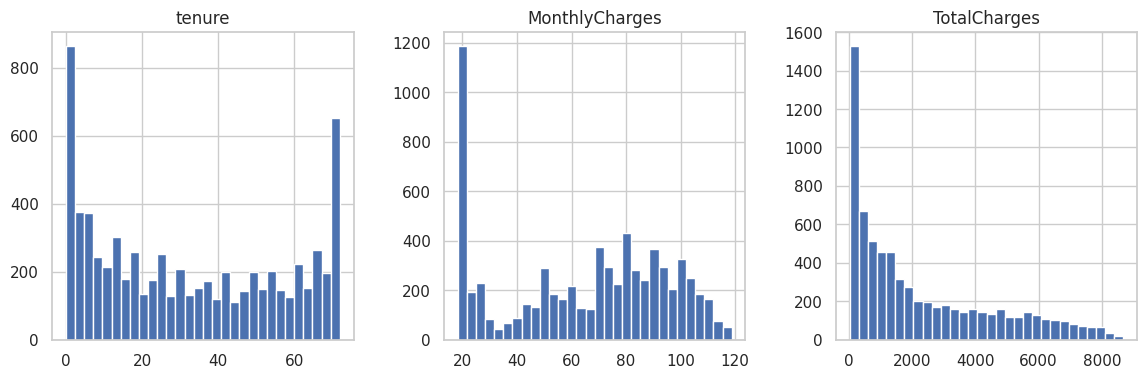

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Numeric columns: histograms
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[numeric_cols].hist(bins=30, figsize=(14, 4), layout=(1, 3))
plt.show()

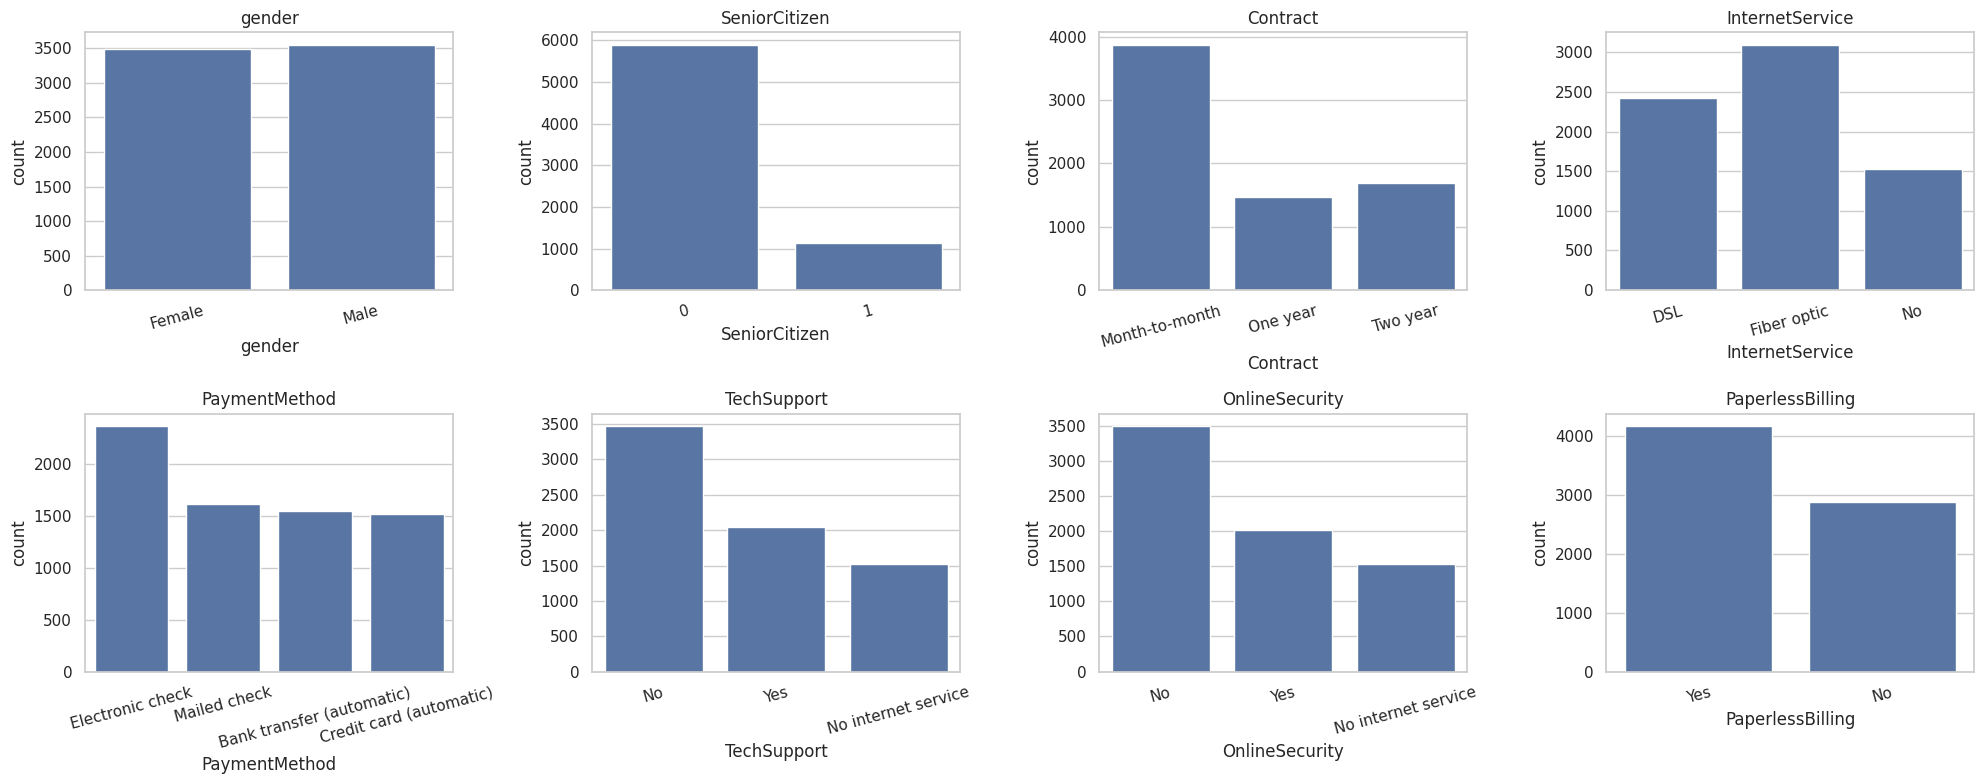

In [13]:
# Some of the text columns: count plots
cat_cols = ["gender", "SeniorCitizen", "Contract", "InternetService",
            "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

**What we notice**

- `tenure`: many customers are very new and many have stayed a long time.
- `TotalCharges` is skewed: most customers have a small total and a few have a very large one.
- The customers are split almost equally between male and female. Most customers are not senior citizens.
- Month-to-month is the most common contract.

### 7. Target Variable Analysis

How many customers churned? This is the column we want to predict.

In [14]:
df['Churn'].value_counts()

df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


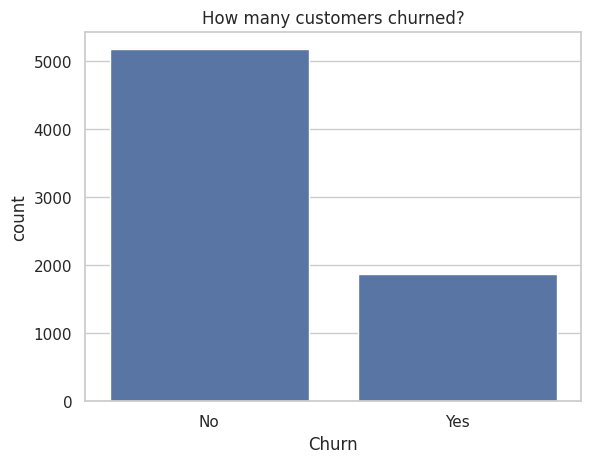

In [15]:
sns.countplot(data=df, x="Churn")
plt.title("How many customers churned?")
plt.show()

**Important:** only about **1 in 4** customers churned (the data is *imbalanced*). A lazy model that always says "stays" would already be right about 73% of the time, so **accuracy alone is not enough**. Later we also look at *Recall* and *ROC-AUC*.

### 8. Bivariate Analysis

*Bivariate* means looking at **two columns together**: here, each feature against `Churn`. For text columns we plot the **churn rate** (% of customers who left) inside each group.

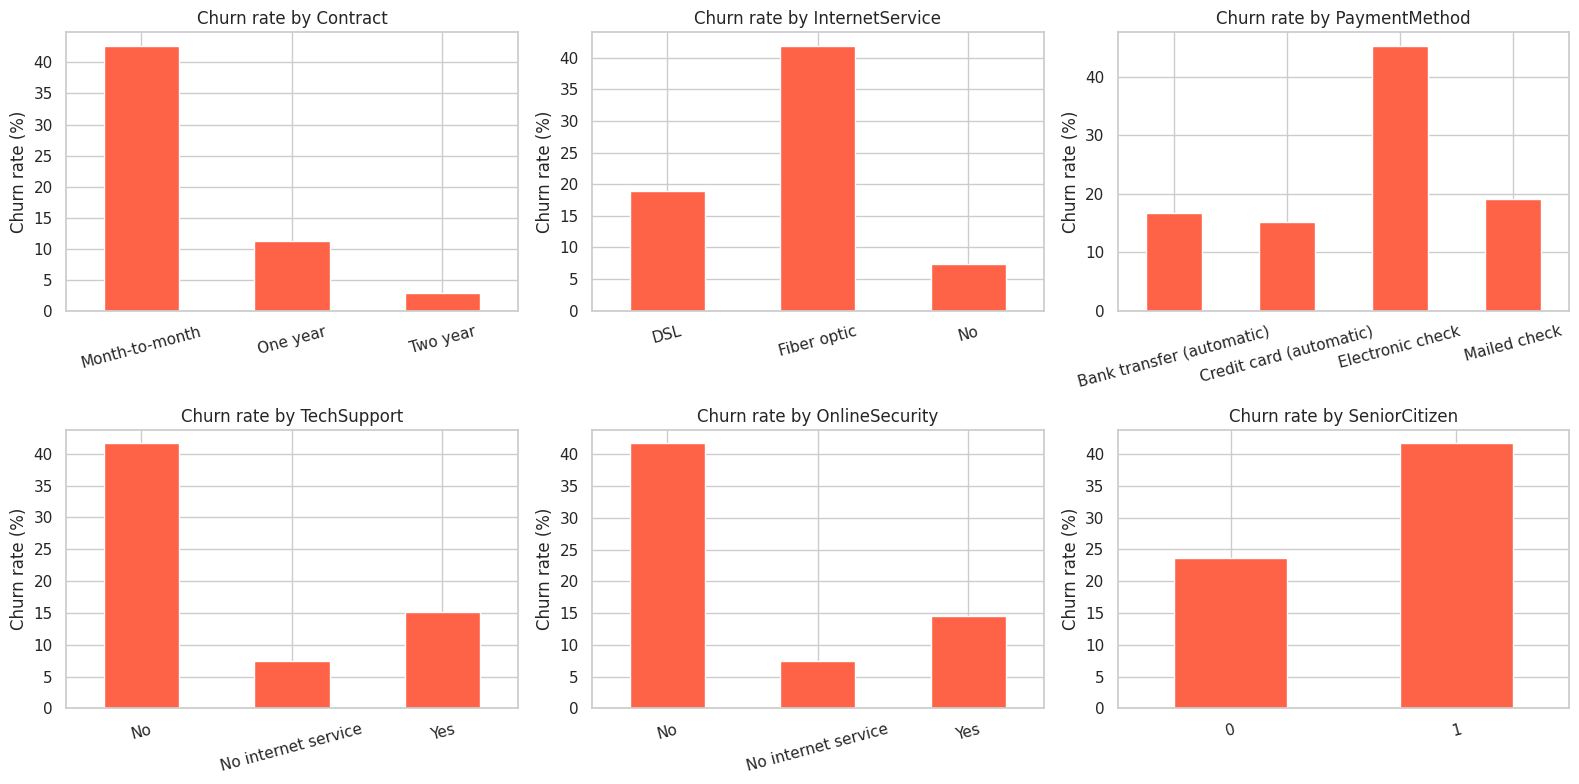

In [16]:
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    # % of customers in each group who churned
    rate = pd.crosstab(df[col], df["Churn"], normalize="index")["Yes"] * 100
    rate.plot(kind="bar", ax=ax, color="tomato")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

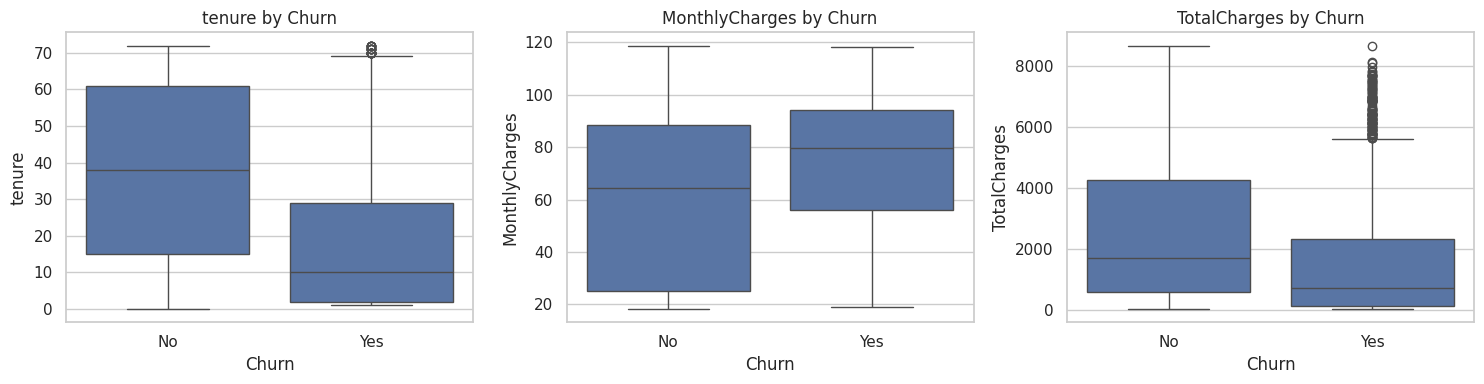

In [17]:
# Numeric columns: compare customers who stayed (No) and left (Yes)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

### 9. Correlation Analysis

Correlation measures how strongly two numeric columns move together (from -1 to +1). We turn `Churn` into 0 / 1 so we can include it.

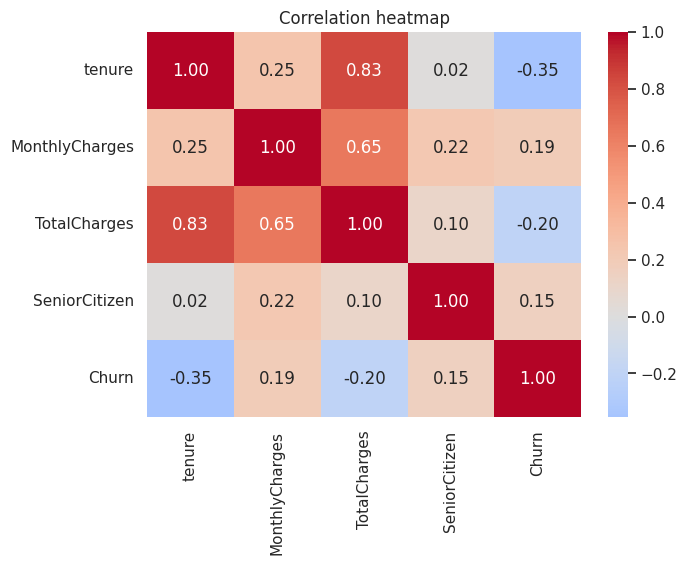

In [18]:
corr_data = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
corr_data["Churn"] = (df["Churn"] == "Yes").astype(int)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

- `tenure` and `TotalCharges` are strongly related (the longer a customer stays, the bigger the total they have paid).
- `tenure` has a **negative** correlation with `Churn`: longer-staying customers are less likely to leave.

### 10. EDA Insights

What the plots tell us (look at the charts above to see how big each difference is):

1. **Contract:** customers on **month-to-month** contracts leave much more than customers on one- or two-year contracts.
2. **Tenure:** **new customers** are the ones who leave most. Long-time customers rarely leave.
3. **Internet service:** **fiber optic** customers leave more than DSL customers.
4. **Payment method:** customers who pay by **electronic check** leave more than the others.
5. **Support services:** customers **without** online security or tech support leave more.
6. **Gender** makes almost no difference.

**What this means for the model:** most columns carry useful information, so we keep them. The data is imbalanced, so we do not trust accuracy alone.

## 03 — DATA PREPROCESSING

### 11. Handling Missing Values

The blank `TotalCharges` values belong to brand-new customers (`tenure = 0`) who have not paid anything yet, so their real total is **0**. We fill them with 0.

In [19]:
missing = df["TotalCharges"].isna()
print("Missing TotalCharges:", missing.sum())
print("Their tenure values :", df.loc[missing, "tenure"].unique())   # all 0, as expected

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing TotalCharges after filling:", df["TotalCharges"].isna().sum())

Missing TotalCharges: 11
Their tenure values : [0]
Missing TotalCharges after filling: 0


### 12. Removing Unnecessary Features

`customerID` is only a label. It does not help predict churn, so we drop it.

In [20]:
df = df.drop(columns=["customerID"], errors="ignore")   # errors="ignore" lets you re-run this cell safely
print("Shape:", df.shape)

Shape: (7043, 20)


### 13. Encoding Categorical Features

A neural network only understands numbers, so we convert the text columns:

- `gender`: Female = 0, Male = 1
- Yes / No columns: No = 0, Yes = 1 (the values "No internet service" and "No phone service" also mean "No")
- `InternetService`, `Contract`, `PaymentMethod`: **one-hot encoding** (one 0/1 column for each possible value)

We put the steps in a small function called `encode`, so we can use **exactly the same steps** later on new customers (Section 26).

In [21]:
yes_no_columns = ["Partner", "Dependents", "PhoneService", "MultipleLines", "OnlineSecurity",
                  "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
                  "StreamingMovies", "PaperlessBilling"]
one_hot_columns = ["InternetService", "Contract", "PaymentMethod"]


def encode(data):
    data = data.copy()
    data["gender"] = data["gender"].map({"Female": 0, "Male": 1})
    for col in yes_no_columns:
        data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})
        data[col] = data[col].map({"No": 0, "Yes": 1})
    return pd.get_dummies(data, columns=one_hot_columns, dtype=int)


y = (df["Churn"] == "Yes").astype(int)     # target: 1 = churn, 0 = stay
X = encode(df.drop(columns="Churn"))       # features: all numbers now

print("Features shape:", X.shape)
X.head()

Features shape: (7043, 26)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


### 14. Train / Validation / Test Split

We split the customers into three parts:

- **Train (60%)**: the model learns from it.
- **Validation (20%)**: we use it to compare models and tune settings.
- **Test (20%)**: kept locked until the end, for one fair final check.

`stratify` keeps the same percentage of churners in each part.

In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

Train: 4225 | Validation: 1409 | Test: 1409


### 15. Feature Scaling

Columns like `TotalCharges` (up to thousands) and 0/1 columns have very different sizes, which makes neural networks learn badly. `StandardScaler` puts every column on a similar scale (around 0).

We learn the scaling **from the training data only** (`fit`), then apply it to all three parts (`transform`). This way no information from validation or test leaks into training.

In [23]:
feature_columns = list(X.columns)    # remember the column order (needed in Section 26)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Number of input features:", X_train.shape[1])

Number of input features: 26


## 04 — MODEL BUILDING

### 16. Baseline Model

A **baseline** is a simple model to compare against. We use **Logistic Regression**. If our ANN cannot beat it, the ANN is not worth the extra effort.

How to read the scores (churn = the "positive" class):

| Score | Question it answers |
|---|---|
| **Accuracy** | What % of all customers did we classify correctly? |
| **Precision** | Of the customers we said would leave, how many really left? |
| **Recall** | Of the customers who really left, how many did we catch? |
| **F1** | One number that balances Precision and Recall |
| **ROC-AUC** | How well does the model rank leavers above stayers? (0.5 = random guessing, 1.0 = perfect) |

The helper `get_scores` calculates all of them, and we store every model's predictions in `val_probs` for the comparison in Section 20.

In [24]:
def get_scores(y_true, proba):
    """All scores for churn probabilities (a customer is predicted to churn if probability >= 0.5)."""
    pred = (proba >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
    }


models = {}      # name -> trained model
val_probs = {}   # name -> predicted churn probabilities on the validation set

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

val_probs["Logistic Regression"] = logreg.predict_proba(X_val)[:, 1]
display(pd.DataFrame({"Logistic Regression": get_scores(y_val, val_probs["Logistic Regression"])}).T.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.824,0.698,0.594,0.642,0.86


### 17. Initial ANN

Our first neural network has:

- an **input layer** (one input per feature),
- **2 hidden layers** (16 and 8 neurons, `relu` activation),
- **1 output neuron** with `sigmoid` activation, which gives a probability between 0 and 1 (the probability that the customer churns).

It learns with the `adam` optimizer and `binary_crossentropy` loss (the standard choice for yes/no problems). We train it for 50 epochs with no tricks, to see what happens.

The function `build_model` creates the network. It also has options for Dropout and L2 that we use in the next sections (the defaults of 0 mean "off").

In [25]:
def build_model(units=(16, 8), dropout=0.0, l2_value=0.0):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2_value)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def plot_history(history):
    """Learning curves: train vs validation."""
    plt.figure(figsize=(12, 4))
    for i, (key, title) in enumerate([("loss", "Loss (lower is better)"), ("accuracy", "Accuracy")]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history.history[key], label="train")
        plt.plot(history.history["val_" + key], label="validation")
        plt.title(title)
        plt.xlabel("epoch")
        plt.legend()
    plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 577 (2.25 KB)

 Trainable params: 577 (2.25 KB)

 Non-trainable params: 0 (0.00 B)

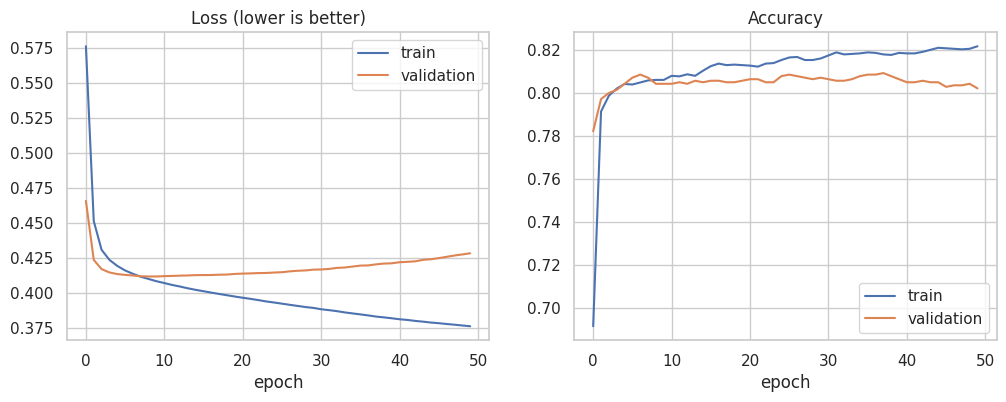

In [26]:
model = build_model()
model.summary()

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=50, batch_size=32, verbose=0)
plot_history(history)

models["ANN - initial"] = model
val_probs["ANN - initial"] = model.predict(X_val, verbose=0).ravel()

**How to read the curves.** The *train* line keeps improving because the network can always memorise the training customers better. If the *validation* line stops improving (or gets worse) while the *train* line keeps improving, that is **overfitting**. The next section tries to reduce it.

### 18. Regularization Experiments

Three ways to fight overfitting:

| Trick | Idea |
|---|---|
| **Dropout** | Randomly switch off some neurons during training, so the network cannot depend on any one neuron |
| **L2** | Punish very large weights, so the model stays simpler |
| **Early stopping** | Stop training when the validation loss stops improving, and keep the best version |

We try Dropout, L2, and Dropout with Early stopping.

In [27]:
histories = {}

# 1) Dropout
model = build_model(dropout=0.3)
histories["Dropout"] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                 epochs=50, batch_size=32, verbose=0)
models["ANN - Dropout"] = model

# 2) L2
model = build_model(l2_value=0.001)
histories["L2"] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=50, batch_size=32, verbose=0)
models["ANN - L2"] = model

# 3) Dropout + Early stopping (stop after 5 epochs without improvement)
model = build_model(dropout=0.3)
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
histories["Dropout + Early stopping"] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                                  epochs=50, batch_size=32, callbacks=[early_stop], verbose=0)
models["ANN - Dropout + EarlyStop"] = model

# Save the predictions of the three models
for name in ["ANN - Dropout", "ANN - L2", "ANN - Dropout + EarlyStop"]:
    val_probs[name] = models[name].predict(X_val, verbose=0).ravel()

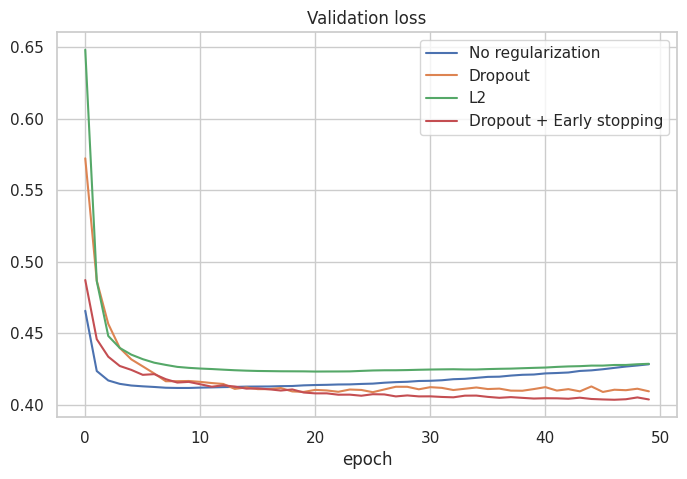

In [28]:
# Compare the validation loss of all versions (lower is better)
plt.figure(figsize=(8, 5))
plt.plot(history.history["val_loss"], label="No regularization")
for name, h in histories.items():
    plt.plot(h.history["val_loss"], label=name)
plt.title("Validation loss")
plt.xlabel("epoch")
plt.legend()
plt.show()

**What to look for.** The version whose validation loss stays low (and does not climb back up) is handling overfitting better. Note that early stopping ends training sooner, so its line is shorter.

### 19. Hyperparameter Tuning

*Hyperparameters* are settings we choose ourselves, such as how many neurons to use or how much Dropout. Instead of guessing, we try a few combinations and keep the one with the best **validation ROC-AUC**. (This is called *grid search*.)

We try 2 network sizes x 3 Dropout values = 6 models. Each one uses early stopping.

In [29]:
best_auc = 0

for units in [(16, 8), (32, 16)]:
    for dropout in [0.0, 0.2, 0.4]:
        model = build_model(units=units, dropout=dropout)
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=100, batch_size=32, callbacks=[stop], verbose=0)

        proba = model.predict(X_val, verbose=0).ravel()
        auc = roc_auc_score(y_val, proba)
        print(f"neurons={units}, dropout={dropout}  ->  validation AUC = {auc:.3f}")

        if auc > best_auc:                       # keep the best model so far
            best_auc, best_units, best_dropout = auc, units, dropout
            models["ANN - tuned"] = model
            val_probs["ANN - tuned"] = proba

print(f"\nBest settings: neurons={best_units}, dropout={best_dropout} (AUC = {best_auc:.3f})")

neurons=(16, 8), dropout=0.0  ->  validation AUC = 0.845
neurons=(16, 8), dropout=0.2  ->  validation AUC = 0.853
neurons=(16, 8), dropout=0.4  ->  validation AUC = 0.856
neurons=(32, 16), dropout=0.0  ->  validation AUC = 0.851
neurons=(32, 16), dropout=0.2  ->  validation AUC = 0.852
neurons=(32, 16), dropout=0.4  ->  validation AUC = 0.856

Best settings: neurons=(32, 16), dropout=0.4 (AUC = 0.856)


## 05 — EVALUATION

### 20. Model Comparison

All models side by side on the **validation set**. (The test set is still untouched.)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.824,0.698,0.594,0.642,0.860
ANN - initial,0.802,0.646,0.561,0.601,0.839
ANN - Dropout,0.808,0.707,0.471,0.565,0.852
ANN - L2,0.809,0.666,0.564,0.611,0.850
ANN - Dropout + EarlyStop,0.816,0.705,0.529,0.605,0.856
ANN - tuned,0.820,0.699,0.564,0.624,0.856


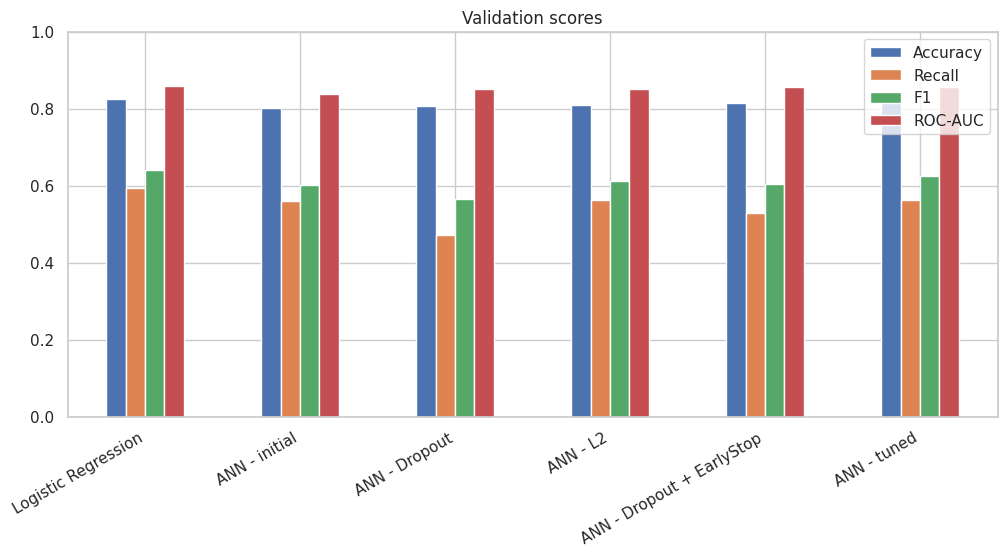

Best ANN on the validation set: ANN - Dropout + EarlyStop


In [30]:
comparison = pd.DataFrame({name: get_scores(y_val, p) for name, p in val_probs.items()}).T.round(3)
display(comparison)

comparison[["Accuracy", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(12, 5))
plt.title("Validation scores")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.show()

# The winner: the ANN with the best validation ROC-AUC
ann_only = comparison[comparison.index.str.startswith("ANN")]
best_name = ann_only["ROC-AUC"].idxmax()
print("Best ANN on the validation set:", best_name)

**How to choose.** Look mainly at **ROC-AUC** and **Recall**, not only Accuracy. If two models are very close, the simpler one is usually the better choice.

### 21. Confusion Matrix

A confusion matrix counts the right and wrong predictions. Now we use the **test set for the first time**, only for the winner from Section 20 (and the baseline, for comparison).

- Top-left: stayed, predicted *Stay* (correct)
- Bottom-right: left, predicted *Churn* (correct)
- Top-right: stayed, but predicted *Churn* (false alarm)
- Bottom-left: left, but predicted *Stay* (a **missed churner**, the most costly mistake)

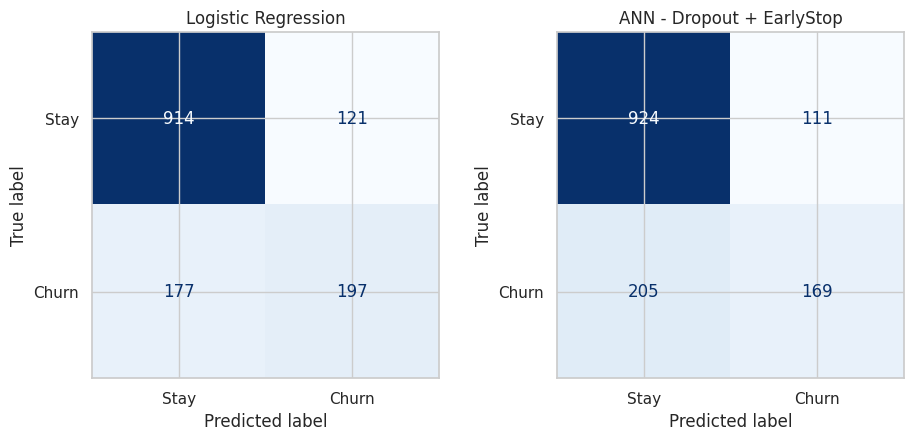

In [31]:
best_model = models[best_name]
test_proba = best_model.predict(X_test, verbose=0).ravel()
lr_test_proba = logreg.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, proba) in zip(axes, [("Logistic Regression", lr_test_proba), (best_name, test_proba)]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int),
                                            display_labels=["Stay", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.show()

### 22. ROC Curve

The ROC curve shows how well a model separates leavers from stayers at **every** possible cut-off. The closer the curve is to the top-left corner (bigger AUC), the better. The dashed diagonal line is random guessing.

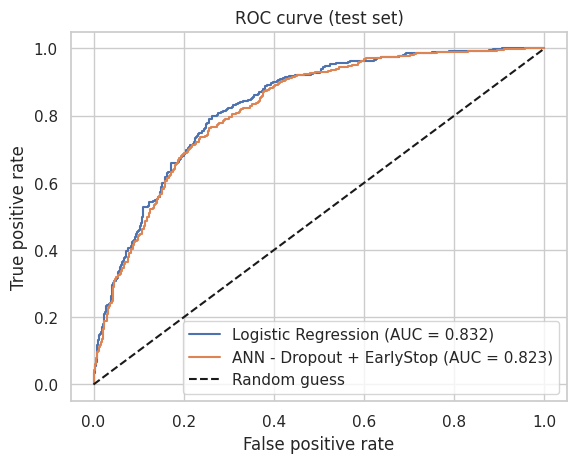

In [32]:
for name, proba in [("Logistic Regression", lr_test_proba), (best_name, test_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

### 23. Final Model Selection

The steps were:

1. Train several models on the **train** set.
2. Compare them on the **validation** set and pick the best ANN (Section 20).
3. Check that one winner **once** on the **test** set (below). We never go back and change the model after seeing the test result.

In [33]:
test_table = pd.DataFrame({
    "Logistic Regression": get_scores(y_test, lr_test_proba),
    best_name: get_scores(y_test, test_proba),
}).T.round(3)
display(test_table)

ann_auc = test_table.iloc[1]["ROC-AUC"]
lr_auc = test_table.iloc[0]["ROC-AUC"]
if ann_auc > lr_auc + 0.005:
    print(f"The ANN is better than the baseline (AUC {ann_auc} vs {lr_auc}).")
elif ann_auc < lr_auc - 0.005:
    print(f"The baseline is slightly better (AUC {lr_auc} vs {ann_auc}).")
else:
    print(f"The ANN and the baseline are about equal (AUC {ann_auc} vs {lr_auc}).")

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.789,0.619,0.527,0.569,0.832
ANN - Dropout + EarlyStop,0.776,0.604,0.452,0.517,0.823


The baseline is slightly better (AUC 0.832 vs 0.823).


**Final choice:** the best ANN from the validation comparison. On a small table like this one, a simple Logistic Regression is often just as good as a neural network, and that is a normal result, not a mistake. We keep the ANN here because it is the goal of the project.

## 06 — FINAL PIPELINE

### 24. Save Best Model

To use the model later we save **three** things: the trained network, the scaler, and the list of feature columns.

In [34]:
best_model.save("best_model.keras")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(feature_columns, "feature_columns.pkl")
print("Saved: best_model.keras, scaler.pkl, feature_columns.pkl")

Saved: best_model.keras, scaler.pkl, feature_columns.pkl


### 25. Load Best Model

We load the three files back, as a new notebook would do, and check that the loaded model gives the same predictions.

In [35]:
loaded_model = keras.models.load_model("best_model.keras")
loaded_scaler = joblib.load("scaler.pkl")
loaded_columns = joblib.load("feature_columns.pkl")

same = np.allclose(loaded_model.predict(X_test, verbose=0), best_model.predict(X_test, verbose=0))
print("Loaded model gives the same predictions:", same)

Loaded model gives the same predictions: True


### 26. Inference Function

*Inference* means using the trained model on **new** data. The function `predict_churn` takes one customer (a dictionary with the same fields as the original dataset, without `customerID` and `Churn`) and repeats the same steps as in training: encode, line up the columns, scale, predict.

In [36]:
def predict_churn(customer):
    new = pd.DataFrame([customer])                           # one row
    new = encode(new)                                        # same encoding as training
    new = new.reindex(columns=loaded_columns, fill_value=0)  # same columns, same order
    new = loaded_scaler.transform(new)                       # same scaling
    probability = loaded_model.predict(new, verbose=0)[0][0]
    label = "Will churn" if probability >= 0.5 else "Will stay"
    return label, probability

In [37]:
customer_1 = {   # new customer, month-to-month contract, fiber optic, electronic check
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.5, "TotalCharges": 190.0,
}
customer_2 = {   # long-time customer, two-year contract, DSL, with support services
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 60,
    "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
    "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
    "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 62.0, "TotalCharges": 3700.0,
}

for i, customer in enumerate([customer_1, customer_2], start=1):
    label, probability = predict_churn(customer)
    print(f"Customer {i}: {label}  (probability of churn = {probability:.1%})")

Customer 1: Will churn  (probability of churn = 76.8%)
Customer 2: Will stay  (probability of churn = 0.4%)


### 27. Final Conclusion

**What we did**

1. Loaded the data and checked it. The only problem was a few blank `TotalCharges` values (new customers), which we filled with 0.
2. Explored the data and found what is linked to churn.
3. Prepared the data: encoded text as numbers, split into train / validation / test, and scaled.
4. Built a baseline (Logistic Regression) and an ANN, reduced overfitting with Dropout, L2 and early stopping, and tried a small grid of settings.
5. Picked the best ANN on the validation set, checked it once on the test set, saved it, and wrote `predict_churn` for new customers.

**What leads customers to churn:** a short time with the company, month-to-month contracts, fiber optic internet, paying by electronic check, and not having security or tech-support services.

**Results:** see the table in Section 23. The ANN is compared with the baseline there.

**Limits and next steps**

- Only 1 in 4 customers churns, so models tend to **miss** some churners (low Recall). Ideas: give churners more weight when training (`class_weight`), or predict "churn" at a lower probability than 0.5.
- Try other models (Random Forest, XGBoost) and compare.
- Use cross-validation for more reliable scores.